In [1]:
# ===== 0. Set Seed untuk Reprodusibilitas =====
import os
import random
import numpy as np

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

    # Jika pakai TensorFlow/Keras
    try:
        import tensorflow as tf
        tf.random.set_seed(seed)
        os.environ['TF_DETERMINISTIC_OPS'] = '1'
    except ImportError:
        pass

    # Jika pakai PyTorch
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except ImportError:
        pass

set_seed(SEED)
print(f"✅ Seed diset ke {SEED}")

I0000 00:00:1783509338.580452    7745 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1783509338.936011    7745 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1783509340.758383    7745 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


✅ Seed diset ke 42


In [2]:
# ===== 1. Set Path Dataset (lokal, tanpa Google Drive) =====
import os
from PIL import Image
import pandas as pd

BASE_DIR = "/home/farel/projects/BDC2026"   # ganti kalau lokasi projectmu beda
DATA_DIR = os.path.join(BASE_DIR, "train")

if not os.path.exists(DATA_DIR):
    print(f"⚠️ Path tidak ditemukan: {DATA_DIR}")
    print("Isi folder BASE_DIR kamu:")
    print(os.listdir(BASE_DIR))
else:
    print(f"✅ Path ditemukan: {DATA_DIR}")
    print("Isi folder:", os.listdir(DATA_DIR))

✅ Path ditemukan: /home/farel/projects/BDC2026/train
Isi folder: ['0_Recyclable', '1_Electronic', '2_Organic']


In [3]:
# ===== 4. Scan Dataset =====
records = []
corrupt_files = []

for class_folder in os.listdir(DATA_DIR):
    class_path = os.path.join(DATA_DIR, class_folder)
    if not os.path.isdir(class_path):
        continue
    for fname in os.listdir(class_path):
        fpath = os.path.join(class_path, fname)
        try:
            with Image.open(fpath) as img:
                w, h = img.size
                mode = img.mode
                records.append({
                    "class": class_folder,
                    "filename": fname,
                    "width": w,
                    "height": h,
                    "ratio": round(w / h, 2),
                    "mode": mode,
                    "filesize_kb": os.path.getsize(fpath) / 1024
                })
        except Exception as e:
            corrupt_files.append((fpath, str(e)))

df = pd.DataFrame(records)

print("=== Jumlah File Terbaca vs Total ===")
print(f"Terbaca: {len(df)}, Corrupt: {len(corrupt_files)}")

print("\n=== Ringkasan Ukuran (width/height) per Kelas ===")
print(df.groupby("class")[["width", "height"]].describe()[["width", "height"]])

print("\n=== Ukuran Paling Umum (Top 5) ===")
print(df.groupby(["width", "height"]).size().sort_values(ascending=False).head(5))

print("\n=== Distribusi Rasio Aspek per Kelas ===")
print(df.groupby("class")["ratio"].describe())

print("\n=== Mode Warna ===")
print(df.groupby(["class", "mode"]).size())

print(f"\n=== File Corrupt: {len(corrupt_files)} ===")
for f, err in corrupt_files[:10]:
    print(f, "-", err)

print(f"\n=== File Ukuran Kecil (<50KB) per Kelas ===")
print(df[df["filesize_kb"] < 50].groupby("class").size())

print(f"\n=== Statistik Ukuran File (KB) ===")
print(df.groupby("class")["filesize_kb"].describe())

=== Jumlah File Terbaca vs Total ===
Terbaca: 26527, Corrupt: 0

=== Ringkasan Ukuran (width/height) per Kelas ===
                width                                                       \
                count        mean          std    min    25%    50%    75%   
class                                                                        
0_Recyclable   9999.0  242.278028    44.344578   56.0  224.0  225.0  274.0   
1_Electronic   3961.0  604.729866  1026.225142  150.0  150.0  150.0  648.0   
2_Organic     12567.0  260.308586    42.455091   51.0  225.0  263.0  279.0   

                       height                                               \
                 max    count        mean         std    min    25%    50%   
class                                                                        
0_Recyclable   569.0   9999.0  211.659866   34.154425   88.0  183.0  224.0   
1_Electronic  8000.0   3961.0  515.038879  835.293545  113.0  150.0  150.0   
2_Organic      600.0  1256

In [4]:
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from PIL import Image, ImageOps
import pandas as pd
import numpy as np
import glob

print("TF version:", tf.__version__)
print("GPU tersedia:", tf.config.list_physical_devices('GPU'))

TF version: 2.21.0
GPU tersedia: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


W0000 00:00:1783509686.613444    7745 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


In [5]:
DATA_DIR = os.path.join(BASE_DIR, "train")
TEST_DIR = os.path.join(BASE_DIR, "test")
SUBMISSION_TEMPLATE = os.path.join(BASE_DIR, "submission.csv")
OUTPUT_DIR = os.path.join(BASE_DIR, "output")
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMG_SIZE = 224
BATCH_SIZE = 32   # turunkan ke 16 kalau muncul OutOfMemoryError saat fine-tuning (VRAM 8GB)
CLASS_NAMES = ["0_Recyclable", "1_Electronic", "2_Organic"]
LABEL_MAP = {"0_Recyclable": 0, "1_Electronic": 1, "2_Organic": 2}
NUM_CLASSES = 3

In [6]:
filepaths = []
labels = []

for class_folder in CLASS_NAMES:
    class_path = os.path.join(DATA_DIR, class_folder)
    for fname in os.listdir(class_path):
        filepaths.append(os.path.join(class_path, fname))
        labels.append(LABEL_MAP[class_folder])

df = pd.DataFrame({"filepath": filepaths, "label": labels})
print("Total data:", len(df))
print(df["label"].value_counts())

Total data: 26527
label
2    12567
0     9999
1     3961
Name: count, dtype: int64


In [7]:
train_df, val_df = train_test_split(
    df, test_size=0.15, stratify=df["label"], random_state=SEED
)
print("Train:", len(train_df), "Val:", len(val_df))
print("Distribusi train:\n", train_df["label"].value_counts())
print("Distribusi val:\n", val_df["label"].value_counts())

Train: 22547 Val: 3980
Distribusi train:
 label
2    10681
0     8499
1     3367
Name: count, dtype: int64
Distribusi val:
 label
2    1886
0    1500
1     594
Name: count, dtype: int64


In [8]:
class_weights_arr = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df["label"]),
    y=train_df["label"]
)
class_weight_dict = dict(enumerate(class_weights_arr))
print("Class weights:", class_weight_dict)

Class weights: {0: np.float64(0.8843001137388712), 1: np.float64(2.232155232155232), 2: np.float64(0.7036482227007459)}


In [9]:
def load_and_preprocess(filepath, label, augment=False):
    def _load(fp):
        fp = fp.numpy().decode("utf-8")
        img = Image.open(fp).convert("RGB")
        img = ImageOps.pad(img, (IMG_SIZE, IMG_SIZE), color=(0, 0, 0))
        return np.array(img, dtype=np.float32)

    img = tf.py_function(_load, [filepath], tf.float32)
    img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    img = preprocess_input(img)

    if augment:
        img = tf.image.random_flip_left_right(img)
        img = tf.image.random_brightness(img, max_delta=0.15)
        img = tf.image.random_contrast(img, lower=0.85, upper=1.15)

    label = tf.one_hot(label, NUM_CLASSES)
    return img, label

def make_dataset(df, augment=False, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((df["filepath"].values, df["label"].values))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=SEED)
    ds = ds.map(lambda fp, lb: load_and_preprocess(fp, lb, augment=augment),
                num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, augment=True, shuffle=True)
val_ds = make_dataset(val_df, augment=False, shuffle=False)

W0000 00:00:1783509938.088023    7745 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1783509938.284683    7745 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5262 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a


In [10]:
def build_model():
    base_model = EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base_model.trainable = False

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = models.Model(inputs, outputs)
    return model, base_model

model, base_model = build_model()
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,926 (16.07 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [11]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)
reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6
)
checkpoint_stage1 = callbacks.ModelCheckpoint(
    os.path.join(OUTPUT_DIR, "model_stage1.keras"),
    monitor="val_loss", save_best_only=True
)

history_stage1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weight_dict,
    callbacks=[early_stop, reduce_lr, checkpoint_stage1]
)

Epoch 1/15


/home/farel/tf-env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1783510022.712587    9887 cuda_dnn.cc:461] Loaded cuDNN version 92400


705/705 ━━━━━━━━━━━━━━━━━━━━ 197s 232ms/step - accuracy: 0.9058 - loss: 0.2362 - val_accuracy: 0.9367 - val_loss: 0.1659 - learning_rate: 0.0010
Epoch 2/15
705/705 ━━━━━━━━━━━━━━━━━━━━ 143s 203ms/step - accuracy: 0.9336 - loss: 0.1610 - val_accuracy: 0.9462 - val_loss: 0.1446 - learning_rate: 0.0010
Epoch 3/15
705/705 ━━━━━━━━━━━━━━━━━━━━ 141s 200ms/step - accuracy: 0.9430 - loss: 0.1372 - val_accuracy: 0.9475 - val_loss: 0.1398 - learning_rate: 0.0010
Epoch 4/15
705/705 ━━━━━━━━━━━━━━━━━━━━ 143s 202ms/step - accuracy: 0.9512 - loss: 0.1191 - val_accuracy: 0.9505 - val_loss: 0.1393 - learning_rate: 0.0010
Epoch 5/15
705/705 ━━━━━━━━━━━━━━━━━━━━ 142s 201ms/step - accuracy: 0.9542 - loss: 0.1075 - val_accuracy: 0.9508 - val_loss: 0.1282 - learning_rate: 0.0010
Epoch 6/15
705/705 ━━━━━━━━━━━━━━━━━━━━ 141s 200ms/step - accuracy: 0.9592 - loss: 0.0958 - val_accuracy: 0.9518 - val_loss: 0.1286 - learning_rate: 0.0010
Epoch 7/15
705/705 ━━━━━━━━━━━━━━━━━━━━ 142s 201ms/step - accuracy: 0.9600 

In [12]:
base_model.trainable = True

fine_tune_at = int(len(base_model.layers) * 0.7)
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Callback baru khusus Stage 2 — patience lebih longgar karena fine-tuning
# konvergen lebih lambat dibanding Stage 1
early_stop_stage2 = callbacks.EarlyStopping(
    monitor="val_loss", patience=8, restore_best_weights=True, verbose=1
)
reduce_lr_stage2 = callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=4, min_lr=1e-7, verbose=1
)
checkpoint_stage2 = callbacks.ModelCheckpoint(
    os.path.join(OUTPUT_DIR, "model_stage2_best.keras"),
    monitor="val_loss", save_best_only=True, verbose=1
)

history_stage2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weight_dict,
    callbacks=[early_stop_stage2, reduce_lr_stage2, checkpoint_stage2]
)

Epoch 1/30


E0000 00:00:1783512703.429263    7745 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


705/705 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step - accuracy: 0.9084 - loss: 0.2603
Epoch 1: val_loss improved from None to 0.20299, saving model to /home/farel/projects/BDC2026/output/model_stage2_best.keras

Epoch 1: finished saving model to /home/farel/projects/BDC2026/output/model_stage2_best.keras
705/705 ━━━━━━━━━━━━━━━━━━━━ 218s 281ms/step - accuracy: 0.9084 - loss: 0.2603 - val_accuracy: 0.9369 - val_loss: 0.2030 - learning_rate: 1.0000e-05
Epoch 2/30
705/705 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.9305 - loss: 0.1778
Epoch 2: val_loss improved from 0.20299 to 0.17748, saving model to /home/farel/projects/BDC2026/output/model_stage2_best.keras

Epoch 2: finished saving model to /home/farel/projects/BDC2026/output/model_stage2_best.keras
705/705 ━━━━━━━━━━━━━━━━━━━━ 165s 234ms/step - accuracy: 0.9305 - loss: 0.1778 - val_accuracy: 0.9430 - val_loss: 0.1775 - learning_rate: 1.0000e-05
Epoch 3/30
705/705 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step - accuracy: 0.9426 - loss: 0.1430
Epoch 

In [ ]:
# base_model.trainable = True

# fine_tune_at = int(len(base_model.layers) * 0.7)
# for layer in base_model.layers[:fine_tune_at]:
#     layer.trainable = False

# model.compile(
#     optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
#     loss="categorical_crossentropy",
#     metrics=["accuracy"]
# )

# checkpoint_stage2 = callbacks.ModelCheckpoint(
#     os.path.join(OUTPUT_DIR, "model_stage2_best.keras"),
#     monitor="val_loss", save_best_only=True
# )

# history_stage2 = model.fit(
#     train_ds,
#     validation_data=val_ds,
#     epochs=20,
#     class_weight=class_weight_dict,
#     callbacks=[early_stop, reduce_lr, checkpoint_stage2]
# )

Epoch 1/20
705/705 ━━━━━━━━━━━━━━━━━━━━ 361s 484ms/step - accuracy: 0.9065 - loss: 0.2501 - val_accuracy: 0.9302 - val_loss: 0.1927 - learning_rate: 1.0000e-05
Epoch 2/20
705/705 ━━━━━━━━━━━━━━━━━━━━ 333s 473ms/step - accuracy: 0.9293 - loss: 0.1818 - val_accuracy: 0.9349 - val_loss: 0.1787 - learning_rate: 1.0000e-05
Epoch 3/20
705/705 ━━━━━━━━━━━━━━━━━━━━ 328s 465ms/step - accuracy: 0.9350 - loss: 0.1577 - val_accuracy: 0.9437 - val_loss: 0.1580 - learning_rate: 1.0000e-05
Epoch 4/20
705/705 ━━━━━━━━━━━━━━━━━━━━ 330s 469ms/step - accuracy: 0.9411 - loss: 0.1430 - val_accuracy: 0.9440 - val_loss: 0.1535 - learning_rate: 5.0000e-06
Epoch 5/20
705/705 ━━━━━━━━━━━━━━━━━━━━ 330s 469ms/step - accuracy: 0.9436 - loss: 0.1350 - val_accuracy: 0.9445 - val_loss: 0.1516 - learning_rate: 5.0000e-06


In [13]:
val_labels_true = val_df["label"].values
val_preds_prob = model.predict(val_ds)
val_preds = np.argmax(val_preds_prob, axis=1)

macro_f1 = f1_score(val_labels_true, val_preds, average="macro")
print(f"\n=== Macro F1-Score (Validation): {macro_f1:.4f} ===")
print("\nClassification Report:")
print(classification_report(val_labels_true, val_preds, target_names=CLASS_NAMES))
print("\nConfusion Matrix:")
print(confusion_matrix(val_labels_true, val_preds))

125/125 ━━━━━━━━━━━━━━━━━━━━ 25s 184ms/step

=== Macro F1-Score (Validation): 0.9611 ===

Classification Report:
              precision    recall  f1-score   support

0_Recyclable       0.95      0.95      0.95      1500
1_Electronic       0.97      0.98      0.98       594
   2_Organic       0.96      0.96      0.96      1886

    accuracy                           0.96      3980
   macro avg       0.96      0.96      0.96      3980
weighted avg       0.96      0.96      0.96      3980


Confusion Matrix:
[[1419   15   66]
 [   8  583    3]
 [  73    3 1810]]


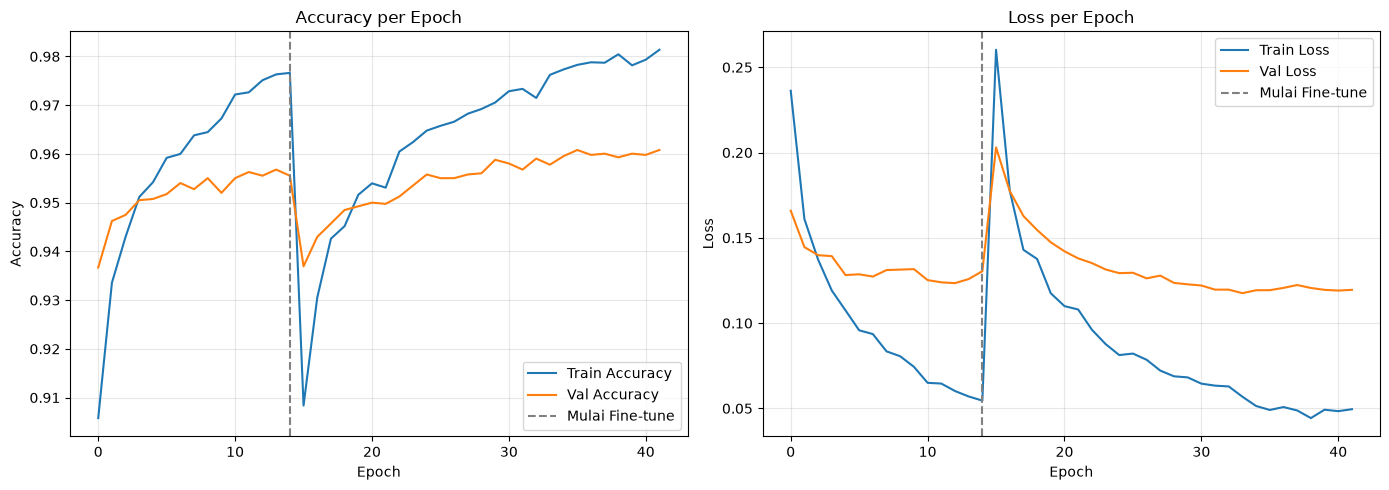

In [14]:
import matplotlib.pyplot as plt

def plot_training_history(history1, history2):
    # gabungkan history stage 1 dan stage 2
    acc = history1.history['accuracy'] + history2.history['accuracy']
    val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']
    loss = history1.history['loss'] + history2.history['loss']
    val_loss = history1.history['val_loss'] + history2.history['val_loss']

    stage1_epochs = len(history1.history['accuracy'])

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Plot Accuracy
    axes[0].plot(acc, label='Train Accuracy')
    axes[0].plot(val_acc, label='Val Accuracy')
    axes[0].axvline(x=stage1_epochs - 1, color='gray', linestyle='--', label='Mulai Fine-tune')
    axes[0].set_title('Accuracy per Epoch')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Plot Loss
    axes[1].plot(loss, label='Train Loss')
    axes[1].plot(val_loss, label='Val Loss')
    axes[1].axvline(x=stage1_epochs - 1, color='gray', linestyle='--', label='Mulai Fine-tune')
    axes[1].set_title('Loss per Epoch')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "training_curves.png"), dpi=150)
    plt.show()

plot_training_history(history_stage1, history_stage2)

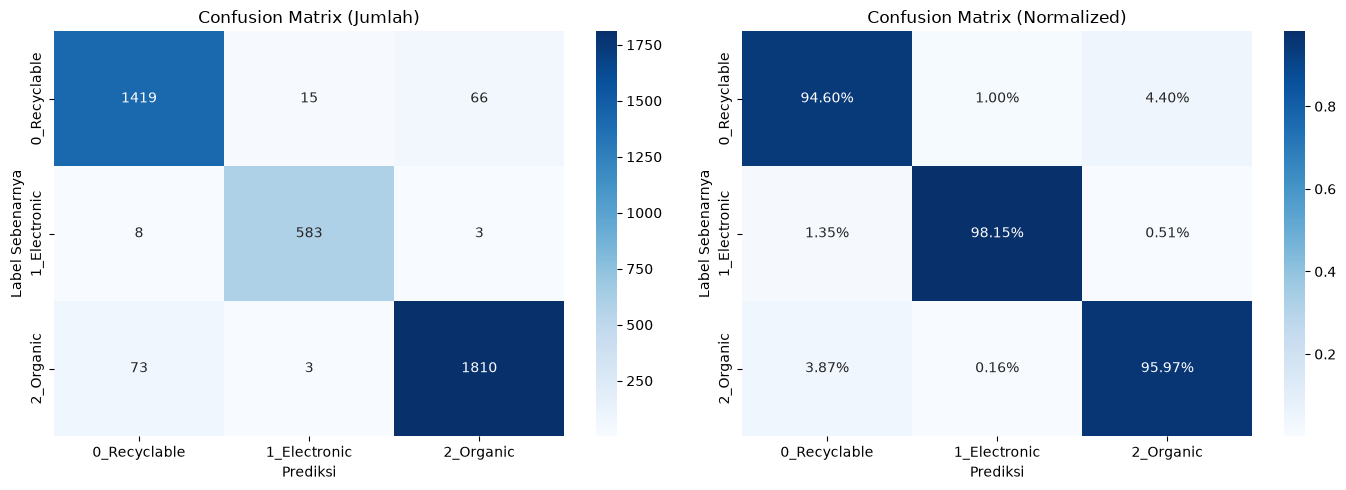

In [15]:
import seaborn as sns

def plot_confusion_matrix(y_true, y_pred, class_names):
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Confusion matrix - jumlah absolut
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title('Confusion Matrix (Jumlah)')
    axes[0].set_xlabel('Prediksi')
    axes[0].set_ylabel('Label Sebenarnya')

    # Confusion matrix - normalized (persentase per kelas)
    sns.heatmap(cm_normalized, annot=True, fmt='.2%', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[1])
    axes[1].set_title('Confusion Matrix (Normalized)')
    axes[1].set_xlabel('Prediksi')
    axes[1].set_ylabel('Label Sebenarnya')

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix.png"), dpi=150)
    plt.show()

plot_confusion_matrix(val_labels_true, val_preds, CLASS_NAMES)

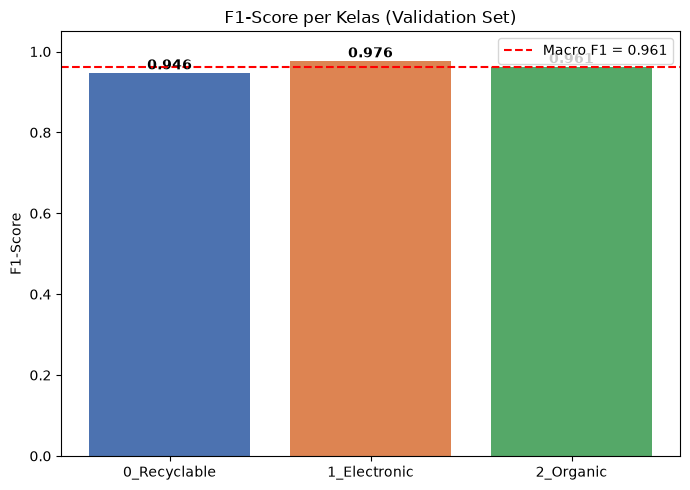

In [16]:
def plot_f1_per_class(y_true, y_pred, class_names):
    f1_scores = f1_score(y_true, y_pred, average=None)
    macro = f1_score(y_true, y_pred, average="macro")

    fig, ax = plt.subplots(figsize=(7, 5))
    bars = ax.bar(class_names, f1_scores, color=['#4C72B0', '#DD8452', '#55A868'])
    ax.axhline(y=macro, color='red', linestyle='--', label=f'Macro F1 = {macro:.3f}')

    for bar, score in zip(bars, f1_scores):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{score:.3f}', ha='center', fontweight='bold')

    ax.set_ylim(0, 1.05)
    ax.set_ylabel('F1-Score')
    ax.set_title('F1-Score per Kelas (Validation Set)')
    ax.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "f1_per_class.png"), dpi=150)
    plt.show()

plot_f1_per_class(val_labels_true, val_preds, CLASS_NAMES)

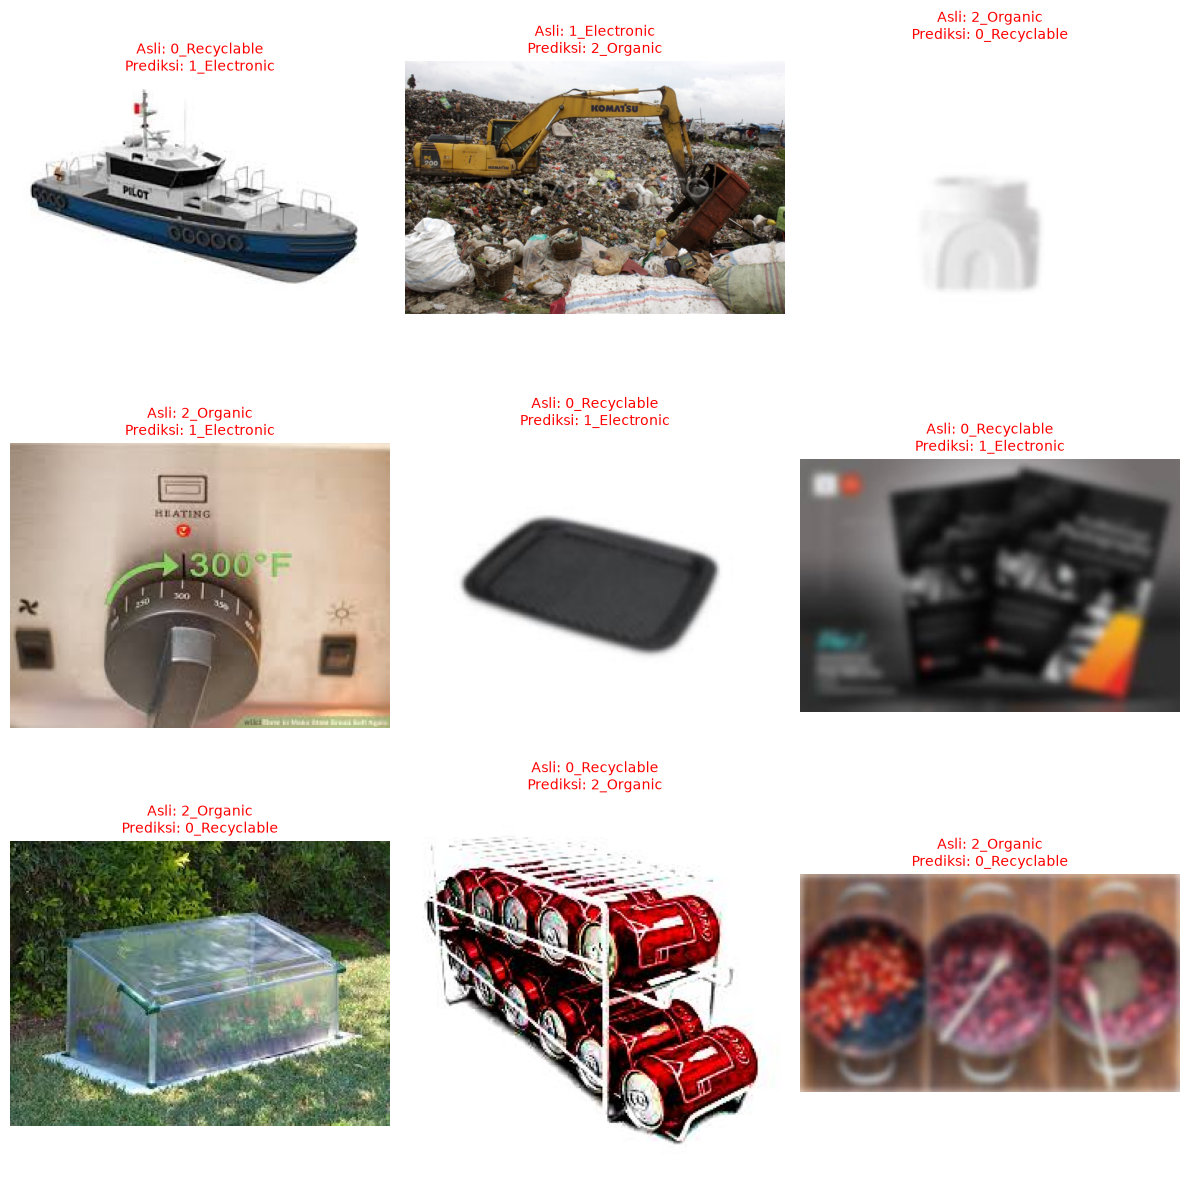

In [17]:
def show_misclassified_examples(val_df, y_true, y_pred, class_names, n_examples=9):
    val_df_reset = val_df.reset_index(drop=True)
    misclassified_idx = np.where(y_true != y_pred)[0]

    if len(misclassified_idx) == 0:
        print("Tidak ada yang salah klasifikasi!")
        return

    sample_idx = np.random.choice(misclassified_idx,
                                    size=min(n_examples, len(misclassified_idx)),
                                    replace=False)

    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    for i, idx in enumerate(sample_idx):
        row, col = i // 3, i % 3
        img_path = val_df_reset.iloc[idx]["filepath"]
        img = Image.open(img_path).convert("RGB")

        axes[row, col].imshow(img)
        axes[row, col].set_title(
            f"Asli: {class_names[y_true[idx]]}\nPrediksi: {class_names[y_pred[idx]]}",
            fontsize=10, color='red'
        )
        axes[row, col].axis('off')

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "misclassified_examples.png"), dpi=150)
    plt.show()

show_misclassified_examples(val_df, val_labels_true, val_preds, CLASS_NAMES)

# Cell 14 dan 15

In [18]:
sub_template = pd.read_csv(SUBMISSION_TEMPLATE)
print(sub_template.head())
print("Kolom submission:", sub_template.columns.tolist())

def find_test_filepath(test_id):
    for ext in ["jpg", "jpeg", "png"]:
        candidate = os.path.join(TEST_DIR, f"{test_id}.{ext}")
        if os.path.exists(candidate):
            return candidate
    matches = glob.glob(os.path.join(TEST_DIR, f"{test_id}.*"))
    if matches:
        return matches[0]
    raise FileNotFoundError(f"Test file untuk id {test_id} tidak ditemukan")

test_filepaths = [find_test_filepath(tid) for tid in sub_template["id"]]

def load_test_image(fp):
    img = Image.open(fp).convert("RGB")
    img = ImageOps.pad(img, (IMG_SIZE, IMG_SIZE), color=(0, 0, 0))
    arr = np.array(img, dtype=np.float32)
    arr = preprocess_input(arr)
    return arr

test_images = np.stack([load_test_image(fp) for fp in test_filepaths])
test_preds_prob = model.predict(test_images, batch_size=BATCH_SIZE)
test_preds = np.argmax(test_preds_prob, axis=1)

   id  predicted
0   1        NaN
1   2        NaN
2   3        NaN
3   4        NaN
4   5        NaN
Kolom submission: ['id', 'predicted']


E0000 00:00:1783519854.547361    7745 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


46/46 ━━━━━━━━━━━━━━━━━━━━ 17s 133ms/step


In [20]:
submission = sub_template.copy()
submission["predicted"] = test_preds

TEAM_NAME = "EpicGlory"  # ganti dengan nama tim kamu
submission_path = os.path.join(OUTPUT_DIR, f"submission_{TEAM_NAME}.csv")
submission.to_csv(submission_path, index=False)
print(f"Submission disimpan di: {submission_path}")
print(submission["predicted"].value_counts())

Submission disimpan di: /home/farel/projects/BDC2026/output/submission_EpicGlory.csv
predicted
2    777
0    473
1    208
Name: count, dtype: int64


# Cell Perbaikan

In [18]:
model = tf.keras.models.load_model(os.path.join(OUTPUT_DIR, "model_stage2_best.keras"))
print("Model checkpoint terbaik berhasil dimuat")

Model checkpoint terbaik berhasil dimuat


In [19]:
def load_and_preprocess_v2(filepath, label, augment=False):
    def _load(fp):
        fp = fp.numpy().decode("utf-8")
        img = Image.open(fp).convert("RGB")
        img = ImageOps.pad(img, (IMG_SIZE, IMG_SIZE), color=(0, 0, 0))
        return np.array(img, dtype=np.float32)

    img = tf.py_function(_load, [filepath], tf.float32)
    img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    img = preprocess_input(img)

    if augment:
        img = tf.image.random_flip_left_right(img)
        img = tf.image.random_brightness(img, max_delta=0.2)
        img = tf.image.random_contrast(img, lower=0.8, upper=1.2)
        img = tf.image.random_saturation(img, lower=0.7, upper=1.3)
        img = tf.image.random_hue(img, max_delta=0.05)

    label = tf.one_hot(label, NUM_CLASSES)
    return img, label

def make_dataset_v2(df, augment=False, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((df["filepath"].values, df["label"].values))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=SEED)
    ds = ds.map(lambda fp, lb: load_and_preprocess_v2(fp, lb, augment=augment),
                num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

train_ds_v2 = make_dataset_v2(train_df, augment=True, shuffle=True)
val_ds_v2 = make_dataset_v2(val_df, augment=False, shuffle=False)

In [20]:
# Cari base_model di dalam model yang sudah di-load
base_model = model.get_layer(index=1)  # cek index yang benar dengan model.summary() kalau error
base_model.trainable = True

fine_tune_at = int(len(base_model.layers) * 0.5)  # buka lebih banyak dari sebelumnya (30% -> 50%)
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-6),  # lebih kecil karena lanjut dari model yang sudah baik
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,926 (16.07 MB)

 Trainable params: 3,243,487 (12.37 MB)

 Non-trainable params: 970,439 (3.70 MB)

In [21]:
early_stop_v2 = callbacks.EarlyStopping(
    monitor="val_loss", patience=6, restore_best_weights=True, verbose=1
)
reduce_lr_v2 = callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-8, verbose=1
)
checkpoint_v2 = callbacks.ModelCheckpoint(
    os.path.join(OUTPUT_DIR, "model_stage3_best.keras"),
    monitor="val_loss", save_best_only=True, verbose=1
)

history_stage3 = model.fit(
    train_ds_v2,
    validation_data=val_ds_v2,
    epochs=15,
    class_weight=class_weight_dict,
    callbacks=[early_stop_v2, reduce_lr_v2, checkpoint_v2]
)

Epoch 1/15
705/705 ━━━━━━━━━━━━━━━━━━━━ 0s 446ms/step - accuracy: 0.9370 - loss: 0.7428
Epoch 1: val_loss improved from None to 0.64204, saving model to /content/drive/MyDrive/bdc2026/output/model_stage3_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/bdc2026/output/model_stage3_best.keras
705/705 ━━━━━━━━━━━━━━━━━━━━ 389s 522ms/step - accuracy: 0.9370 - loss: 0.6935 - val_accuracy: 0.9392 - val_loss: 0.6420 - learning_rate: 5.0000e-06
Epoch 2/15
705/705 ━━━━━━━━━━━━━━━━━━━━ 0s 437ms/step - accuracy: 0.9289 - loss: 0.5997
Epoch 2: val_loss improved from 0.64204 to 0.56990, saving model to /content/drive/MyDrive/bdc2026/output/model_stage3_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/bdc2026/output/model_stage3_best.keras
705/705 ━━━━━━━━━━━━━━━━━━━━ 360s 511ms/step - accuracy: 0.9258 - loss: 0.5910 - val_accuracy: 0.9352 - val_loss: 0.5699 - learning_rate: 5.0000e-06
Epoch 3/15
705/705 ━━━━━━━━━━━━━━━━━━━━ 0s 439ms/step - accuracy: 0.9209 - 

# Melakukan Penambahan Epoch dari SetPoint sebelumnya




In [22]:
early_stop_v2 = callbacks.EarlyStopping(
    monitor="val_loss", patience=8, restore_best_weights=True, verbose=1
)
reduce_lr_v2 = callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=4, min_lr=1e-8, verbose=1
)
checkpoint_v2 = callbacks.ModelCheckpoint(
    os.path.join(OUTPUT_DIR, "model_stage3_best.keras"),
    monitor="val_loss", save_best_only=True, verbose=1
)

history_stage3_extra = model.fit(
    train_ds_v2,
    validation_data=val_ds_v2,
    initial_epoch=15,   # lanjut dari epoch 15
    epochs=30,          # total target 30 epoch
    class_weight=class_weight_dict,
    callbacks=[early_stop_v2, reduce_lr_v2, checkpoint_v2]
)

Epoch 16/30
705/705 ━━━━━━━━━━━━━━━━━━━━ 0s 439ms/step - accuracy: 0.9478 - loss: 0.4435
Epoch 16: val_loss improved from None to 0.43631, saving model to /content/drive/MyDrive/bdc2026/output/model_stage3_best.keras

Epoch 16: finished saving model to /content/drive/MyDrive/bdc2026/output/model_stage3_best.keras
705/705 ━━━━━━━━━━━━━━━━━━━━ 359s 509ms/step - accuracy: 0.9475 - loss: 0.4396 - val_accuracy: 0.9472 - val_loss: 0.4363 - learning_rate: 5.0000e-06
Epoch 17/30
705/705 ━━━━━━━━━━━━━━━━━━━━ 0s 435ms/step - accuracy: 0.9511 - loss: 0.4366
Epoch 17: val_loss improved from 0.43631 to 0.43368, saving model to /content/drive/MyDrive/bdc2026/output/model_stage3_best.keras

Epoch 17: finished saving model to /content/drive/MyDrive/bdc2026/output/model_stage3_best.keras
705/705 ━━━━━━━━━━━━━━━━━━━━ 358s 507ms/step - accuracy: 0.9488 - loss: 0.4364 - val_accuracy: 0.9472 - val_loss: 0.4337 - learning_rate: 5.0000e-06
Epoch 18/30
705/705 ━━━━━━━━━━━━━━━━━━━━ 0s 473ms/step - accuracy: 0.

KeyboardInterrupt: 

In [ ]:
val_labels_true = val_df["label"].values
val_preds_prob_v2 = model.predict(val_ds_v2)
val_preds_v2 = np.argmax(val_preds_prob_v2, axis=1)

macro_f1_v2 = f1_score(val_labels_true, val_preds_v2, average="macro")
print(f"=== Macro F1-Score Iterasi 2: {macro_f1_v2:.4f} ===")
print(f"=== Macro F1-Score Iterasi 1 (sebelumnya): 0.9305 ===")
print(f"Selisih: {macro_f1_v2 - 0.9305:+.4f}")

print("\nClassification Report:")
print(classification_report(val_labels_true, val_preds_v2, target_names=CLASS_NAMES))
print("\nConfusion Matrix:")
print(confusion_matrix(val_labels_true, val_preds_v2))

# Visualisasi ulang
plot_confusion_matrix(val_labels_true, val_preds_v2, CLASS_NAMES)
plot_f1_per_class(val_labels_true, val_preds_v2, CLASS_NAMES)